# 07 — Results Analysis: EFCIL × Attention untuk Scene Classification Citra Satelit

**Tujuan:** melakukan audit dan analisis **hasil production**, bukan smoke/profiling. Notebook ini membaca hasil `run_experiment()` dari PyCIL; **tidak memulai training**, tidak memodifikasi checkpoint, dan dapat dijalankan ketika sebagian eksperimen belum selesai.

Urutan: **(1)** konfigurasi sumber data → **(2)** audit kelengkapan & konsistensi → **(3)** coverage eksperimen → **(4)** tabel AIA/LTA/FR/BWT/Macro-F1 → **(5)** paired attention gain → **(6)** grafik akurasi per task & confusion matrix → **(7)** ekspor laporan.

**Metodologi yang dikunci:** AID 600×600, NWPU 256×256; seed split/class-order 1993; AID T5 `[14,4,4,4,4]` / T10 `[12,2×9]`; NWPU T5 `[25,5×4]` / T10 `[18,3×9]`; empat attention `none`, `eca`, `cbam`, `procbam`. Evaluasi menggunakan classifier canonical yang telah digunakan runner (FeTrIL = Linear SVM; FeCAM = Mahalanobis; PASS/SSRE/EFC = output CNN canonical), sehingga **tidak melakukan inferensi ulang**.

### Interpretasi statistik
- **AIA** = rata-rata akurasi joint pada semua task, **LTA** = akurasi joint task terakhir.
- **ΔAIA** = AIA(attention) − AIA(none) pada **dataset × metode × T × backbone × seed** yang sama; dilaporkan dalam *percentage points (pp)*.
- **Mean ΔAIA / Attention Gain** = rata-rata delta atas *paired runs* yang tersedia, **bukan** rata-rata semua angka absolut tanpa pasangan.
- **Win Rate** = proporsi paired runs dengan ΔAIA > 0.
- Standar deviasi delta yang ditampilkan adalah variasi antarkondisi backbone/T, **bukan antarseed**. Dengan satu seed, **jangan mengklaim signifikansi statistik**.
- FR/BWT diambil dari metrik canonical runner; FWT berstatus **not applicable**, tidak diisi nilai palsu.

> Keamanan: file `.npz`/`.npy` dibaca dengan `allow_pickle=False`. Notebook **tidak** membuka `.pkl` secara otomatis. Checkpoint dicek keberadaan/ukuran dan manifest-nya. Pemeriksaan loadable penuh harus dilakukan pada lingkungan repository tepercaya menggunakan verifier production terpisah.

## 1. Setup & direktori sumber

**Disarankan menjalankan notebook ini pada PC2** setelah mengumpulkan hasil server. Struktur contoh:

```text
PyCIL/
├── outputs/experiments/                        # hasil lokal PC2
├── analysis_inputs/server/experiments/          # hasil export server, ekstraksi ZIP
├── notebooks/07_results_analysis.ipynb
└── outputs/analysis/                             # CSV, JSON, PNG dari notebook
```

Untuk menyalin hasil server tanpa `.pkl` model yang berukuran besar, gunakan script pendamping `scripts/export_evaluation_artifacts.py`; ia mencatat **checkpoint inventory** (bukti file ada pada mesin sumber saat ekspor). Hasil ekspor tanpa bobot checkpoint akan ditandai `ready_snapshot`, bukan `ready_full`. Jika Anda menyalin semua file termasuk `.pkl`, status dapat menjadi `ready_full`.

Jika notebook dijalankan pada server atau lokasi lain, sesuaikan `SOURCES`. Jangan menghapus hasil run lama atau menganggap status `completed` saja cukup.

In [1]:
from __future__ import annotations

import io, json, math, re, warnings, zipfile
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Lokasi otomatis untuk notebook di PyCIL/ atau PyCIL/notebooks/
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

# EDIT PATH di sini bila menjalankan dari komputer berbeda.
SOURCES = {
    "pc2": PROJECT_ROOT / "outputs" / "experiments",
    "server": PROJECT_ROOT / "analysis_inputs" / "server" / "experiments",
}
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "analysis"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables_bab4"
AI_READY_DIR = PROJECT_ROOT / "outputs" / "analysis_ai_ready"
AI_CROSSCHECK_DIR = OUTPUT_DIR / "ai_crosscheck"
for path in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, AI_CROSSCHECK_DIR):
    path.mkdir(parents=True, exist_ok=True)

# File .pkl tidak dibuka; model checkpoint hanya dicek keberadaan dan ukuran.
ALLOW_CHECKPOINT_INVENTORY = True   # izinkan ready_snapshot dari ZIP export
EXPECTED_SEED = 1993
DATASET_SCOPE = "aid"               # gunakan None untuk semua dataset yang ditemukan
GENERATE_FIGURES = True

ATTENTIONS = ("none", "eca", "cbam", "procbam")
PAIR_ATTENTIONS = ("eca", "cbam", "procbam")
METHODS = ("fetril", "fecam", "ssre", "efc", "pass")
BACKBONES = ("r18", "r34")
PROTOCOLS = ("T5", "T10")
METHOD_LABELS = {"fetril": "FeTrIL", "fecam": "FeCAM", "ssre": "SSRE", "efc": "EFC", "pass": "PASS"}
ATTN_LABELS = {"none": "None", "eca": "ECA", "cbam": "CBAM", "procbam": "ProCBAM"}

print("PROJECT_ROOT:", PROJECT_ROOT)
for name, path in SOURCES.items():
    print(f"{name:>8}:", path, "| exists:", path.is_dir())
print("Output:", OUTPUT_DIR)
print("Figures:", FIG_DIR)
print("Tables:", TABLE_DIR)
print("AI crosscheck:", AI_CROSSCHECK_DIR)


PROJECT_ROOT: C:\Skripsi\Project\PyCIL
     pc2: C:\Skripsi\Project\PyCIL\outputs\experiments | exists: True
  server: C:\Skripsi\Project\PyCIL\analysis_inputs\server\experiments | exists: True
Output: C:\Skripsi\Project\PyCIL\outputs\analysis
Figures: C:\Skripsi\Project\PyCIL\outputs\analysis\figures
Tables: C:\Skripsi\Project\PyCIL\outputs\analysis\tables_bab4
AI crosscheck: C:\Skripsi\Project\PyCIL\outputs\analysis\ai_crosscheck


## 2. Fungsi audit dan ekstraksi metadata

Audit menggunakan schema `production_section.py` yang sudah kita bahas: `status.json`, `config.json`, `effective_args.json`, `provenance.json`, `summary.json`, `continual_metrics.json`, `task_metrics.json`, prediksi `task_XX.npz`, confusion matrix per task/final, dan tiga checkpoint artifact per task.

Sebuah run hanya masuk analisis jika **semua task selesai dan evaluasinya konsisten**. ZIP export tanpa bobot model tetap dapat digunakan untuk *analisis metrik* bila inventory checkpoint menyatakan ada file-file itu pada sumber, tetapi perlu diverifikasi kembali di sumber untuk audit final.

In [2]:
def read_json(path: Path):
    with path.open("r", encoding="utf-8-sig") as fh:
        return json.load(fh)


def numeric(value):
    if isinstance(value, bool) or value is None:
        return np.nan
    try:
        result = float(value)
        return result if np.isfinite(result) else np.nan
    except (ValueError, TypeError):
        return np.nan


def safe_float(value):
    value = numeric(value)
    return None if pd.isna(value) else float(value)


def select_value(documents, keys):
    """Ambil nilai dari config/args/provenance tanpa menebak bila tidak ada."""
    for doc in documents:
        if not isinstance(doc, dict):
            continue
        for key in keys:
            if key in doc and doc[key] is not None and not isinstance(doc[key], (dict, list)):
                return doc[key]
        for container in ("config", "args", "experiment", "training", "run_config"):
            sub = doc.get(container)
            if isinstance(sub, dict):
                for key in keys:
                    if key in sub and sub[key] is not None and not isinstance(sub[key], (dict, list)):
                        return sub[key]
    return None


def normalize_metadata(value, kind):
    if value is None:
        return None
    s = str(value).strip().lower().replace("-", "_")
    if kind == "dataset":
        if "resisc" in s or "nwpu" in s: return "nwpu"
        if s in ("aid", "aid30", "aid_dataset"): return "aid"
    if kind == "method":
        for m in METHODS:
            if s == m or s == f"{m}_learner": return m
    if kind == "protocol":
        if s in ("5", "t5", "t_5"): return "T5"
        if s in ("10", "t10", "t_10"): return "T10"
    if kind == "backbone":
        if re.search(r"(?:^|_)r18(?:_|$)", s) or "resnet18" in s or "resnet_18" in s: return "r18"
        if re.search(r"(?:^|_)r34(?:_|$)", s) or "resnet34" in s or "resnet_34" in s: return "r34"
    if kind == "attention":
        if s in ("none", "baseline", "no_attention", "no_attn", "null"): return "none"
        for a in ("procbam", "cbam", "eca"):
            if re.search(r"(?:^|_)" + a + r"(?:_|$)", s): return a
        # Hanya infer none jika field attention sendiri explicit; jangan dari 'r18'.
    if kind == "seed":
        try: return int(value)
        except (ValueError, TypeError): return None
    if kind == "batch":
        try: return int(value)
        except (ValueError, TypeError): return None
    return None


def infer_from_run_name(run_id, kind):
    s = str(run_id).lower().replace("-", "_")
    if kind == "method":
        for m in METHODS:
            if re.search(r"(?:^|_)" + m + r"(?:_|$)", s): return m
    if kind == "dataset":
        for token, normalized in (("aid", "aid"), ("nwpu", "nwpu"), ("resisc45", "nwpu")):
            if re.search(r"(?:^|_)" + token + r"(?:_|$)", s): return normalized
    if kind == "protocol":
        m = re.search(r"(?:^|_)t(5|10)(?:_|$)", s)
        if m: return "T" + m.group(1)
    if kind == "backbone":
        m = re.search(r"(?:^|_)(r18|r34)(?:_|$)", s)
        if m: return m.group(1)
    if kind == "attention":
        for a in ATTENTIONS:
            if re.search(r"(?:^|_)" + a + r"(?:_|$)", s): return a
    if kind == "seed":
        m = re.search(r"(?:^|_)seed_?(\d+)(?:_|$)", s)
        if m: return int(m.group(1))
    return None


def metadata_from_files(run_id, config, args, provenance, summary):
    docs = [config, args, provenance, summary]
    names = {
        "dataset": ["dataset", "dataset_name"],
        "method": ["method", "model_name", "learner_name"],
        "protocol": ["protocol", "task_protocol", "task_setting", "scenario"],
        "backbone": ["backbone", "backbone_type", "backbone_name", "convnet_type"],
        "attention": ["attention", "attention_type", "attention_name", "attn_type"],
        "seed": ["training_seed", "seed", "random_seed"],
        "batch": ["batch_size", "batch"],
    }
    result = {}
    for kind, aliases in names.items():
        raw = select_value(docs, aliases)
        val = normalize_metadata(raw, kind)
        if val is None and kind == "attention":
            # convnet_type/backbone id kadang berupa r34_procbam.
            val = normalize_metadata(select_value(docs, ["convnet_type", "backbone"]), "attention")
        if val is None:
            val = infer_from_run_name(run_id, kind)
        result[kind] = val
    return result


def canonical_primary_top1(primary):
    if not isinstance(primary, dict): return None
    if primary.get("top1") is not None: return safe_float(primary["top1"])
    metric = primary.get("metrics")
    if isinstance(metric, dict): return safe_float(metric.get("top1"))
    return None


def macro_f1_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    pred = cm.sum(axis=0)
    true = cm.sum(axis=1)
    denom = pred + true
    f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return float(np.mean(f1) * 100.0)


def checkpoint_check(run_dir, n_tasks, allow_inventory):
    """Hanya structural check. Tidak memanggil torch.load/pickle.load."""
    ckpt = run_dir / "model_checkpoints"
    inventory_path = run_dir / "checkpoint_inventory.json"
    inv = None
    if allow_inventory and inventory_path.exists():
        inv = read_json(inventory_path).get("inventory")
    full, snapshot = True, isinstance(inv, dict)
    for task_id in range(n_tasks):
        for file_name in (f"model_{task_id}.pkl", f"method_state_{task_id}.pkl"):
            rel = "model_checkpoints/" + file_name
            actual = ckpt / file_name
            exists_full = actual.is_file() and actual.stat().st_size > 0
            full = full and exists_full
            item = inv.get(rel, {}) if isinstance(inv, dict) else {}
            snapshot = snapshot and (
                (isinstance(item, dict) and item.get("exists") is True
                 and isinstance(item.get("size"), int) and item["size"] > 0)
                or exists_full
            )
        manifest_file = ckpt / f"checkpoint_{task_id}.json"
        if not manifest_file.is_file():
            raise ValueError(f"Missing checkpoint manifest: task {task_id}")
        manifest = read_json(manifest_file)
        if not isinstance(manifest, dict) or not {"network_checkpoint", "method_state"}.issubset(manifest):
            raise ValueError(f"Invalid checkpoint manifest: task {task_id}")
    if full: return "full"
    if snapshot: return "snapshot"
    raise ValueError("Missing model/method-state checkpoint (or source inventory)")

In [3]:
EXPECTED_SEEN_CLASSES = {
    ("aid", "T5"): [14, 18, 22, 26, 30],
    ("aid", "T10"): [12, 14, 16, 18, 20, 22, 24, 26, 28, 30],
    ("nwpu", "T5"): [25, 30, 35, 40, 45],
    ("nwpu", "T10"): [18, 21, 24, 27, 30, 33, 36, 39, 42, 45],
}

REQUIRED_CONTINUAL = ("aia", "last_task_accuracy", "forgetting_rate", "bwt",
                      "macro_f1_final", "task_accuracy_matrix", "class_accuracy_matrix")


def audit_run(run_dir: Path, source_machine: str):
    record = {
        "source_machine": source_machine,
        "run_id": run_dir.name,
        "run_dir": str(run_dir),
        "status": "incomplete",
        "issue": "",
        "checkpoint_level": "none",
        "eligible": False,
    }
    try:
        for fname in ("config.json", "effective_args.json", "provenance.json",
                      "summary.json", "status.json", "continual_metrics.json", "task_metrics.json"):
            if not (run_dir / fname).is_file():
                raise ValueError(f"Missing {fname}")

        config, args, provenance, summary, status, cmtr, task_metrics = (
            read_json(run_dir / fname) for fname in
            ("config.json", "effective_args.json", "provenance.json",
             "summary.json", "status.json", "continual_metrics.json", "task_metrics.json")
        )
        meta = metadata_from_files(run_dir.name, config, args, provenance, summary)
        record.update(meta)
        record["reported_state"] = status.get("state") if isinstance(status, dict) else None

        if status.get("state") != "completed":
            raise ValueError(f"status.json state = {status.get('state')!r}")
        if not isinstance(args, dict) or args.get("save_checkpoints") is not True:
            raise ValueError("effective_args.save_checkpoints != true")
        for k in ("dataset", "method", "protocol", "backbone", "attention", "seed", "batch"):
            if meta[k] is None:
                raise ValueError(f"Metadata '{k}' unknown; inspect config.json/effective_args.json")
        if not isinstance(task_metrics, list):
            raise ValueError("task_metrics.json must be a list")
        n_tasks = 5 if meta["protocol"] == "T5" else 10
        if len(task_metrics) != n_tasks:
            raise ValueError(f"Expected {n_tasks} task metrics, found {len(task_metrics)}")
        if not isinstance(cmtr, dict) or any(key not in cmtr for key in REQUIRED_CONTINUAL):
            missing = [key for key in REQUIRED_CONTINUAL if not isinstance(cmtr, dict) or key not in cmtr]
            raise ValueError(f"Missing continual metrics: {missing}")
        curve = []
        seen = []
        last_cm = None
        for tid, metric in enumerate(task_metrics):
            if not isinstance(metric, dict): raise ValueError(f"Invalid task_metrics[{tid}]")
            pred_path = run_dir / "predictions" / f"task_{tid:02d}.npz"
            cm_path = run_dir / "confusion_matrices" / f"task_{tid:02d}.npy"
            if not pred_path.is_file() or not cm_path.is_file():
                raise ValueError(f"Missing predictions/confusion_matrices for task {tid}")
            with np.load(pred_path, allow_pickle=False) as pred:
                if not {"y_true", "y_pred_topk"}.issubset(pred.files):
                    raise ValueError(f"Invalid prediction fields on task {tid}")
                y_true = np.asarray(pred["y_true"])
                y_topk = np.asarray(pred["y_pred_topk"])
            if y_true.ndim != 1 or y_topk.ndim not in (1, 2):
                raise ValueError(f"Invalid prediction dimensions on task {tid}")
            pred_top1 = y_topk[:, 0] if y_topk.ndim == 2 else y_topk
            if len(pred_top1) != len(y_true) or len(y_true) == 0:
                raise ValueError(f"Prediction length mismatch task {tid}")
            seen_classes = int(metric["seen_classes"])
            cm = np.load(cm_path, allow_pickle=False)
            if cm.shape != (seen_classes, seen_classes):
                raise ValueError(f"Confusion shape mismatch task {tid}: {cm.shape}")
            if not np.isfinite(cm).all() or (cm < 0).any():
                raise ValueError(f"Invalid confusion counts task {tid}")
            if int(cm.sum()) != len(y_true):
                raise ValueError(f"Confusion sample count mismatch task {tid}")
            if not (np.issubdtype(y_true.dtype, np.integer) and np.issubdtype(pred_top1.dtype, np.integer)):
                raise ValueError(f"Prediction labels must be integer on task {tid}")
            if ((y_true < 0) | (y_true >= seen_classes)).any() or ((pred_top1 < 0) | (pred_top1 >= seen_classes)).any():
                raise ValueError(f"Prediction label out of range task {tid}")
            actual_cm = np.zeros_like(cm, dtype=np.int64)
            np.add.at(actual_cm, (y_true, pred_top1), 1)
            if not np.array_equal(cm.astype(np.int64), actual_cm):
                raise ValueError(f"Confusion disagrees with canonical predictions task {tid}")
            canonical_top1 = safe_float(metric.get("canonical_top1"))
            calc_top1 = float(np.mean(y_true == pred_top1) * 100)
            if canonical_top1 is None or abs(canonical_top1 - calc_top1) > 0.051:
                raise ValueError(f"Canonical Top-1 mismatch task {tid}")
            primary = canonical_primary_top1(metric.get("primary"))
            if primary is not None and abs(primary - calc_top1) > 0.051:
                raise ValueError(f"Primary Top-1 mismatch task {tid}")
            curve.append(calc_top1)
            seen.append(seen_classes)
            last_cm = cm

        expected = EXPECTED_SEEN_CLASSES.get((meta["dataset"], meta["protocol"]))
        if expected is not None and seen != expected:
            raise ValueError(f"Seen class progression {seen}, expected {expected}")
        final_cm = np.load(run_dir / "final_confusion_matrix.npy", allow_pickle=False)
        if not np.array_equal(final_cm, last_cm):
            raise ValueError("Final confusion matrix differs from last task")
        aia, lta = safe_float(cmtr.get("aia")), safe_float(cmtr.get("last_task_accuracy"))
        if aia is None or lta is None or not (0 <= aia <= 100 and 0 <= lta <= 100):
            raise ValueError("Missing/invalid AIA or LTA")
        if abs(aia - float(np.mean(curve))) > 0.051 or abs(lta - curve[-1]) > 0.051:
            raise ValueError("AIA/LTA do not agree with per-task canonical predictions")
        macro_f1 = macro_f1_from_confusion(final_cm)
        stored_macro = safe_float(cmtr.get("macro_f1_final"))
        if stored_macro is not None:
            # Runner dapat menyimpan F1 0..1 atau dalam persen; cek keduanya.
            if min(abs(stored_macro - macro_f1), abs(stored_macro * 100 - macro_f1)) > 0.15:
                raise ValueError("Macro-F1 disagrees with final confusion matrix")
        checkpoint_level = checkpoint_check(run_dir, n_tasks, ALLOW_CHECKPOINT_INVENTORY)
        record.update({
            "status": "ready_full" if checkpoint_level == "full" else "ready_snapshot",
            "checkpoint_level": checkpoint_level,
            "eligible": True,
            "n_tasks": n_tasks,
            "n_classes_final": seen[-1],
            "aia": aia,
            "lta": lta,
            "macro_f1_pct": macro_f1,
            "fr": safe_float(cmtr.get("forgetting_rate")),
            "bwt": safe_float(cmtr.get("bwt")),
            "fwt_status": cmtr.get("fwt_status", "not_specified"),
            "task_curve": curve,
            "seen_classes_curve": seen,
        })
    except Exception as exc:
        record["issue"] = f"{type(exc).__name__}: {exc}"
        if record.get("reported_state") == "failed": record["status"] = "failed"
        elif record.get("reported_state") == "running": record["status"] = "running"
        else: record["status"] = "incomplete"
    return record

## 3. Scan run dan pemeriksaan konflik/duplikat

**Penting:** bila Anda mengulang training dan menyalin hasil dari dua mesin, bisa saja dua folder menggambarkan konfigurasi identik. Notebook memprioritaskan hasil lengkap, tetapi **menahan hasil yang saling bertentangan** agar rerun lama tidak terhitung dua kali. Periksa tabel `Conflicts` sebelum menganalisis efek attention.

In [4]:
raw_records = []
for source_name, root in SOURCES.items():
    if root.is_dir():
        for run_dir in sorted(p for p in root.iterdir() if p.is_dir()):
            # Hindari direktori non-run, misalnya folder export temporer.
            if not any((run_dir / fn).exists() for fn in ("config.json", "status.json", "task_metrics.json")):
                continue
            raw_records.append(audit_run(run_dir, source_name))

runs_raw = pd.DataFrame(raw_records)
if runs_raw.empty:
    print("Belum ada hasil ditemukan. Periksa SOURCES di sel Setup atau export hasil server.")
    runs = runs_raw.copy()
else:
    runs = runs_raw.copy()
    key_cols = ["dataset", "method", "protocol", "backbone", "attention", "seed"]
    runs["selection_note"] = ""
    eligible_idx = runs.index[runs["eligible"] == True].tolist()
    # Kelompokkan berdasarkan kombinasi eksperimen, bukan path, run_id, atau section.
    for key, indices in runs.loc[eligible_idx].groupby(key_cols, dropna=False).groups.items():
        ids = list(indices)
        if len(ids) <= 1: continue
        ref = runs.loc[ids[0]]
        same = all(
            abs(float(runs.at[i, "aia"]) - float(ref["aia"])) < 1e-7
            and abs(float(runs.at[i, "lta"]) - float(ref["lta"])) < 1e-7
            and np.allclose(runs.at[i, "task_curve"], ref["task_curve"], atol=1e-7)
            for i in ids[1:]
        )
        if not same:
            for i in ids:
                runs.at[i, "eligible"] = False
                runs.at[i, "status"] = "duplicate_conflict"
                runs.at[i, "selection_note"] = "Conflicting metric results for same experiment key"
        else:
            chosen = sorted(ids, key=lambda i: (runs.at[i, "checkpoint_level"] == "full", str(runs.at[i, "run_dir"])), reverse=True)[0]
            for i in ids:
                if i != chosen:
                    runs.at[i, "eligible"] = False
                    runs.at[i, "status"] = "duplicate_copy"
                    runs.at[i, "selection_note"] = f"Identical duplicate of {runs.at[chosen, 'run_dir']}"
    display(runs.groupby(["source_machine", "status"], dropna=False).size().rename("count").reset_index())
    problems = runs[runs["eligible"] != True][["source_machine", "run_id", "status", "issue", "selection_note", "run_dir"]]
    if not problems.empty:
        display(Markdown("**Perlu perhatian — run tidak dipakai dalam analisis:**"))
        display(problems.head(100))

valid = runs.loc[runs["eligible"] == True].copy() if not runs.empty else pd.DataFrame()
if not valid.empty and DATASET_SCOPE is not None:
    valid = valid[valid["dataset"] == DATASET_SCOPE].copy()
print(f"Run terdeteksi: {len(runs)}; valid untuk analisis scope: {len(valid)}")

,source_machine,status,count
0,pc2,ready_snapshot,24
1,server,ready_snapshot,56


Run terdeteksi: 80; valid untuk analisis scope: 80


## 4. Coverage: semua konfigurasi yang seharusnya ada

Untuk active production AID, grid yang direncanakan adalah **5 metode × 2 protocol × 2 backbone × 4 attention = 80 run** (sebelum repeated seed). Notebook tetap menampilkan konfigurasi yang belum ditemukan, termasuk PASS T5 R18 CBAM/ProCBAM dan PASS T5 R34 ProCBAM jika belum selesai recovery.

Status `missing` artinya tidak ada hasil valid, bukan otomatis belum pernah dijalankan. `ready_snapshot` berarti metrik lengkap tetapi `.pkl` diverifikasi melalui inventory export, bukan load checkpoint lokal.

In [5]:
from itertools import product

expected_rows = []
for method, protocol, backbone, attention in product(METHODS, PROTOCOLS, BACKBONES, ATTENTIONS):
    machine = ("pc2" if method in ("pass", "fecam", "ssre") and backbone == "r18" else "server")
    expected_rows.append(dict(dataset="aid", method=method, protocol=protocol,
                              backbone=backbone, attention=attention, seed=EXPECTED_SEED,
                              assigned_machine=machine))
expected_grid = pd.DataFrame(expected_rows)
merge_keys = ["dataset", "method", "protocol", "backbone", "attention", "seed"]
if not valid.empty:
    found = valid[merge_keys + ["status", "source_machine", "aia", "lta", "checkpoint_level"]].copy()
    coverage = expected_grid.merge(found, how="left", on=merge_keys, validate="one_to_one")
else:
    coverage = expected_grid.copy()
    coverage["status"] = np.nan
coverage["coverage"] = coverage["status"].fillna("missing")
coverage["assigned_machine_ok"] = (
    coverage["source_machine"] == coverage["assigned_machine"]
    if "source_machine" in coverage.columns else False
)

print("Ready:", int(coverage["coverage"].str.startswith("ready").sum()), "/", len(coverage))
display(coverage.pivot_table(index=["method", "backbone", "protocol"], columns="attention",
                            values="coverage", aggfunc="first").reindex(columns=list(ATTENTIONS)))
missing = coverage[coverage["coverage"] == "missing"]
if not missing.empty:
    display(Markdown(f"**Belum valid: {len(missing)} konfigurasi**"))
    display(missing[["assigned_machine", "method", "protocol", "backbone", "attention"]].reset_index(drop=True))
if "source_machine" in coverage:
    mismatched_machine = coverage[coverage["coverage"].str.startswith("ready") & ~coverage["assigned_machine_ok"]]
    if not mismatched_machine.empty:
        print("WARNING: Run ditemukan pada mesin berbeda dari assignment production yang direncanakan:")
        display(mismatched_machine)

Ready: 80 / 80


attention                           none             eca            cbam  \
method backbone protocol                                                   
efc    r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
fecam  r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
fetril r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
pass   r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
ssre   r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   

attention                        procbam  
method backbone protocol                  
efc    r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
fecam  r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
fetril r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
pass   r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
ssre   r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot

## 5. Tabel metrik canonical per run

AIA, LTA, Forgetting Rate (FR), dan BWT dibaca dari `continual_metrics.json`; Macro-F1 dihitung ulang dari confusion matrix task terakhir untuk memastikan skala persen. **Semua metrik akurasi yang dihasilkan notebook ini dalam persen, sedangkan Δ dalam *percentage points*.** FR/BWT ditampilkan dalam unit asli yang tersimpan pada runner (periksa implementasi jika ingin memberi label satuan khusus).

In [6]:
if valid.empty:
    print("Belum ada metrik production valid.")
else:
    show_cols = ["dataset", "method", "protocol", "backbone", "attention", "seed",
                 "source_machine", "batch", "checkpoint_level", "aia", "lta", "macro_f1_pct", "fr", "bwt"]
    display(valid[show_cols].sort_values(["method", "protocol", "backbone", "attention"]).round(3))

,dataset,method,protocol,backbone,attention,seed,source_machine,batch,checkpoint_level,aia,lta,macro_f1_pct,fr,bwt
24,aid,efc,T10,r18,cbam,1993,server,12,snapshot,76.619,71.50,71.116,22.663,-15.136
25,aid,efc,T10,r18,eca,1993,server,12,snapshot,70.640,65.90,65.503,27.766,-20.195
26,aid,efc,T10,r18,none,1993,server,12,snapshot,69.856,64.40,62.456,29.056,-18.142
27,aid,efc,T10,r18,procbam,1993,server,12,snapshot,76.042,72.65,72.241,21.322,-13.811
28,aid,efc,T10,r34,cbam,1993,server,12,snapshot,74.002,69.70,69.492,24.111,-17.249
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23,aid,ssre,T5,r18,procbam,1993,pc2,20,snapshot,82.112,73.25,73.649,19.967,-23.152
76,aid,ssre,T5,r34,cbam,1993,server,32,snapshot,79.649,70.55,71.197,20.829,-23.842
77,aid,ssre,T5,r34,eca,1993,server,32,snapshot,80.827,73.80,73.987,18.084,-21.201
78,aid,ssre,T5,r34,none,1993,server,32,snapshot,77.676,69.15,68.889,22.681,-25.832


## 6. Perbandingan berpasangan vs baseline **none**

Hanya dibandingkan pasangan yang memenuhi **dataset + method + T + backbone + seed sama**, dan tambahan kontrol **batch + mesin** sama. Baseline none yang belum lengkap menghalangi perhitungan Δ untuk bundle tersebut; baris tidak boleh diisi nol atau disamakan dengan hasil dari backbone/protocol lain.

In [7]:
def paired_attention_analysis(valid_runs):
    if valid_runs.empty:
        return pd.DataFrame(), pd.DataFrame()
    keys = ["dataset", "method", "protocol", "backbone", "seed"]
    baseline = valid_runs[valid_runs["attention"] == "none"].copy()
    attention = valid_runs[valid_runs["attention"] != "none"].copy()
    cols = keys + ["aia", "lta", "macro_f1_pct", "fr", "bwt", "source_machine", "batch", "run_id"]
    paired = attention.merge(baseline[cols], on=keys, how="inner", suffixes=("_attention", "_none"), validate="many_to_one")
    paired["fair_hardware_batch"] = ((paired["source_machine_attention"] == paired["source_machine_none"])
                                     & (paired["batch_attention"] == paired["batch_none"]))
    rejected = paired[~paired["fair_hardware_batch"]].copy()
    paired = paired[paired["fair_hardware_batch"]].copy()
    for metric in ("aia", "lta", "macro_f1_pct", "fr", "bwt"):
        paired["delta_" + metric] = paired[metric + "_attention"] - paired[metric + "_none"]
    return paired, rejected

paired, rejected_pairs = paired_attention_analysis(valid)
if not rejected_pairs.empty:
    print("ATTENTION: pasangan berikut tidak fair (batch/hardware berbeda) sehingga dikeluarkan:")
    display(rejected_pairs[["dataset", "method", "protocol", "backbone", "attention",
                            "source_machine_none", "source_machine_attention", "batch_none", "batch_attention"]])
if paired.empty:
    print("Belum ada matched pairs yang siap untuk dibandingkan.")
else:
    display(paired[["method", "protocol", "backbone", "attention", "delta_aia", "delta_lta",
                    "delta_macro_f1_pct", "delta_fr", "delta_bwt"]].sort_values(["method", "attention", "protocol", "backbone"]).round(3))

# Mean over observed backbone × T conditions; never fill missing combinations with 0.
if paired.empty:
    gains = pd.DataFrame()
else:
    gains = (paired.groupby(["dataset", "method", "attention"], as_index=False)
             .agg(mean_delta_aia=("delta_aia", "mean"), sd_delta_aia=("delta_aia", "std"),
                  mean_delta_lta=("delta_lta", "mean"), mean_delta_macro_f1=("delta_macro_f1_pct", "mean"),
                  mean_delta_fr=("delta_fr", "mean"), mean_delta_bwt=("delta_bwt", "mean"),
                  n_pairs=("delta_aia", "size"), wins=("delta_aia", lambda s: int((s > 0).sum()))))
    gains["win_rate_pct"] = 100 * gains["wins"] / gains["n_pairs"]
    gains["coverage_4"] = gains["n_pairs"].astype(str) + "/4"
    gains = gains.sort_values("mean_delta_aia", ascending=False)
    display(Markdown("**Mean ΔAIA / Attention Gain (ranking deskriptif; jumlah pair harus diperhatikan):**"))
    display(gains.round(3))
    if (gains["n_pairs"] < 4).any():
        print("NOTE: ada gain dengan < 4 pasangan (R18/R34 × T5/T10); jangan diperlakukan sebagai agregasi final.")

,method,protocol,backbone,attention,delta_aia,delta_lta,delta_macro_f1_pct,delta_fr,delta_bwt
18,efc,T10,r18,cbam,6.763,7.10,8.660,-6.393,3.006
21,efc,T10,r34,cbam,4.426,4.95,6.605,-3.847,-0.044
24,efc,T5,r18,cbam,4.571,5.55,5.406,-3.502,2.054
27,efc,T5,r34,cbam,3.696,4.10,3.988,-2.519,0.090
19,efc,T10,r18,eca,0.784,1.50,3.048,-1.290,-2.053
22,efc,T10,r34,eca,0.637,1.20,2.084,-0.488,-2.749
25,efc,T5,r18,eca,1.478,2.40,2.183,-1.039,0.301
28,efc,T5,r34,eca,1.369,2.00,2.161,-0.408,-0.712
20,efc,T10,r18,procbam,6.185,8.25,9.785,-7.734,4.331
23,efc,T10,r34,procbam,5.945,6.10,7.363,-6.261,1.896


**Mean ΔAIA / Attention Gain (ranking deskriptif; jumlah pair harus diperhatikan):**

,dataset,method,attention,mean_delta_aia,sd_delta_aia,mean_delta_lta,mean_delta_macro_f1,mean_delta_fr,mean_delta_bwt,n_pairs,wins,win_rate_pct,coverage_4
2,aid,efc,procbam,5.429,0.947,6.512,7.497,-6.347,3.976,4,4,100.0,4/4
0,aid,efc,cbam,4.864,1.323,5.425,6.165,-4.065,1.277,4,4,100.0,4/4
13,aid,ssre,eca,4.472,1.328,6.250,6.102,-5.701,6.257,4,4,100.0,4/4
10,aid,pass,eca,4.436,2.816,6.113,6.215,-5.542,6.211,4,4,100.0,4/4
14,aid,ssre,procbam,3.997,1.424,4.300,4.487,-3.504,3.510,4,4,100.0,4/4
7,aid,fetril,eca,3.520,1.610,5.163,4.975,-4.364,4.402,4,4,100.0,4/4
12,aid,ssre,cbam,2.829,1.520,2.862,3.085,-2.010,2.225,4,4,100.0,4/4
11,aid,pass,procbam,2.706,1.745,1.737,1.569,-1.251,1.081,4,4,100.0,4/4
6,aid,fetril,cbam,2.260,1.021,3.125,2.779,-2.224,2.068,4,4,100.0,4/4
8,aid,fetril,procbam,1.817,1.116,2.275,2.077,-2.048,1.716,4,4,100.0,4/4


## 6B. Konfigurasi dengan performa absolut tertinggi

Selain **Attention Gain** (dampak integrasi), tampilkan juga model dengan **AIA/LTA absolut terbaik**. Nilai absolut dan delta menjawab dua pertanyaan yang berbeda: peningkatan terbesar tidak selalu berarti akurasi akhir tertinggi. Bandingkan hanya scope dataset/protocol yang sesuai. Hasil sementara bukan klaim final jika coverage belum lengkap.

In [8]:
if valid.empty:
    print("Belum ada peringkat absolut.")
else:
    for protocol in PROTOCOLS:
        pool = valid[valid.protocol == protocol].copy()
        if pool.empty: continue
        display(Markdown(f"**Top 10 AIA absolut — {protocol} ({DATASET_SCOPE or 'all datasets'})**"))
        display(pool.nlargest(10, "aia")[["method", "backbone", "attention", "source_machine", "aia", "lta", "macro_f1_pct"]].round(2))


**Top 10 AIA absolut — T5 (aid)**

,method,backbone,attention,source_machine,aia,lta,macro_f1_pct
4,fecam,r18,cbam,pc2,88.37,83.10,82.95
7,fecam,r18,procbam,pc2,88.32,82.45,82.16
57,fetril,r18,eca,server,87.81,81.45,81.36
6,fecam,r18,none,pc2,87.66,81.45,80.57
60,fetril,r34,cbam,server,87.63,80.70,80.45
5,fecam,r18,eca,pc2,86.94,80.80,80.46
56,fetril,r18,cbam,server,86.50,78.75,78.71
61,fetril,r34,eca,server,86.13,78.30,78.41
63,fetril,r34,procbam,server,85.88,78.50,78.38
59,fetril,r18,procbam,server,85.67,77.50,77.24


**Top 10 AIA absolut — T10 (aid)**

,method,backbone,attention,source_machine,aia,lta,macro_f1_pct
3,fecam,r18,procbam,pc2,85.83,79.90,79.62
0,fecam,r18,cbam,pc2,85.39,79.25,78.99
53,fetril,r34,eca,server,84.10,77.00,77.02
1,fecam,r18,eca,pc2,83.41,76.10,75.95
2,fecam,r18,none,pc2,83.16,76.20,75.56
49,fetril,r18,eca,server,82.61,74.40,74.14
51,fetril,r18,procbam,server,81.49,71.85,72.05
48,fetril,r18,cbam,server,81.32,72.70,72.45
55,fetril,r34,procbam,server,80.80,71.75,71.66
52,fetril,r34,cbam,server,80.16,70.85,70.54


## 7. Visualisasi peningkatan attention

Heatmap menunjukkan **Mean ΔAIA**, bukan AIA absolut. Bila jumlah pasangan `n<4`, sel tetap bisa tampil sebagai preview tetapi angka tersebut **belum final**. Ranking antar metode sebaiknya dilakukan setelah coverage lengkap dan konsisten.

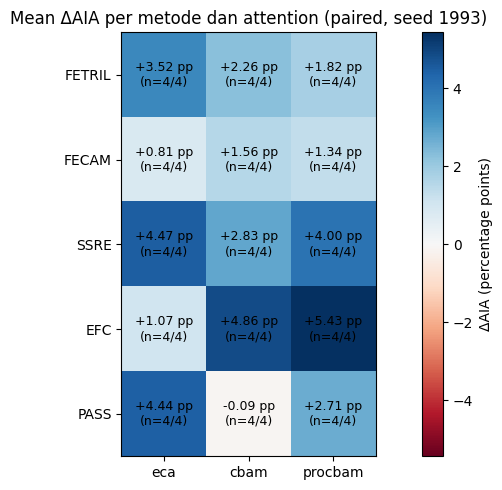

In [9]:
if gains.empty:
    print("Tidak ada gain untuk diplot.")
else:
    matrix = gains.pivot(index="method", columns="attention", values="mean_delta_aia")
    matrix = matrix.reindex(index=list(METHODS), columns=["eca", "cbam", "procbam"])
    counts = gains.pivot(index="method", columns="attention", values="n_pairs").reindex_like(matrix)
    fig, ax = plt.subplots(figsize=(9.5, 5))
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap="RdBu", vmin=-max(1, np.nanmax(np.abs(matrix.to_numpy(dtype=float)))), vmax=max(1, np.nanmax(np.abs(matrix.to_numpy(dtype=float)))))
    ax.set_xticks(range(3), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), [x.upper() for x in matrix.index])
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            v = matrix.iat[i, j]
            if np.isfinite(v):
                n = counts.iat[i, j]
                ax.text(j, i, f"{v:+.2f} pp\n(n={int(n)}/4)", ha="center", va="center", fontsize=9)
    ax.set_title("Mean ΔAIA per metode dan attention (paired, seed 1993)")
    fig.colorbar(image, ax=ax, label="ΔAIA (percentage points)")
    fig.tight_layout()
    if GENERATE_FIGURES: fig.savefig(OUTPUT_DIR / "attention_gain_heatmap.png", dpi=170, bbox_inches="tight")
    plt.show()

## 8. Kurva joint accuracy per incremental task

Ubah pilihan berikut untuk membandingkan seluruh attention pada satu `dataset × method × protocol × backbone`. Perhatikan bahwa kurva T5 memiliki 5 titik, T10 memiliki 10 titik; sebaiknya **tidak ditumpuk pada satu axis tanpa penjelasan**.

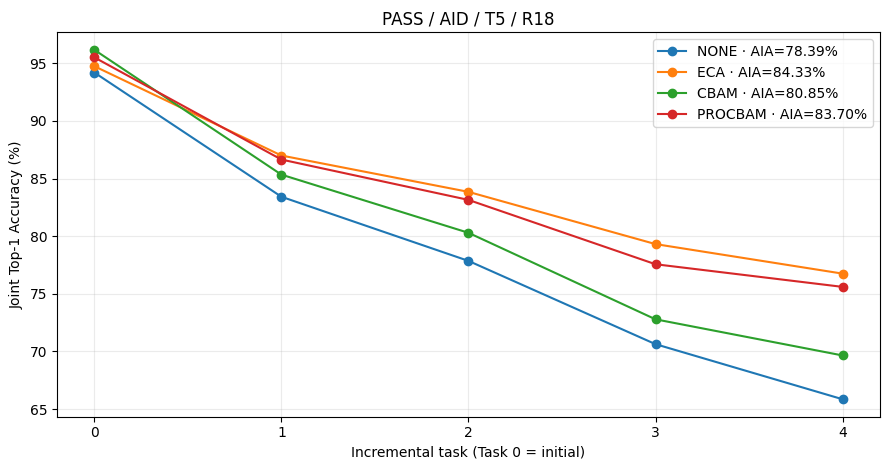

In [10]:
SELECT_DATASET = "aid"
SELECT_METHOD = "pass"        # fetril | fecam | ssre | efc | pass
SELECT_PROTOCOL = "T5"       # T5 | T10
SELECT_BACKBONE = "r18"      # r18 | r34

if valid.empty:
    print("Belum ada kurva valid.")
else:
    subset = valid[(valid.dataset == SELECT_DATASET) & (valid.method == SELECT_METHOD)
                   & (valid.protocol == SELECT_PROTOCOL) & (valid.backbone == SELECT_BACKBONE)]
    if subset.empty:
        print("Tidak ada kurva valid untuk kombinasi ini.")
    else:
        fig, ax = plt.subplots(figsize=(9, 4.8))
        for attention in ATTENTIONS:
            sample = subset[subset.attention == attention]
            if sample.empty: continue
            row = sample.iloc[0]
            curve = row.task_curve
            ax.plot(range(len(curve)), curve, marker="o", label=f"{attention.upper()} · AIA={row.aia:.2f}%")
        ax.set_xlabel("Incremental task (Task 0 = initial)")
        ax.set_ylabel("Joint Top-1 Accuracy (%)")
        ax.set_title(f"{SELECT_METHOD.upper()} / {SELECT_DATASET.upper()} / {SELECT_PROTOCOL} / {SELECT_BACKBONE.upper()}")
        ax.set_xticks(range(5 if SELECT_PROTOCOL == "T5" else 10))
        ax.grid(alpha=.25)
        ax.legend(loc="best")
        fig.tight_layout()
        if GENERATE_FIGURES:
            fig.savefig(OUTPUT_DIR / f"accuracy_curve_{SELECT_METHOD}_{SELECT_DATASET}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}.png", dpi=170)
        plt.show()

## 8B. Diagnostik forgetting dan old/new accuracy

Notebook menghitung ulang akurasi pada kelompok kelas yang sudah pernah dipelajari (*old*) dan kelompok kelas yang baru diperkenalkan pada task tersebut (*new*) dari confusion matrix masing-masing task. Ini berguna untuk mengamati stabilitas/plasticity pada PASS, EFC, dan metode lain.

Berikut juga ditampilkan heatmap **akurasi setiap kelompok task setelah tahap training** dan perbandingan Forgetting Rate/BWT yang direkonstruksi dengan nilai yang disimpan oleh runner. Jika angka berbeda, **hasil runner tetap menjadi metrik pelaporan utama** sampai penyebab perbedaan skala/definisi dikonfirmasi.

**PASS / T5 / R18 / NONE**

,task_id,seen_classes,old_accuracy_pct,new_accuracy_pct,joint_accuracy_pct
0,0,14,NaN,94.20,94.20
1,1,18,81.40,91.38,83.42
2,2,22,74.96,89.31,77.86
3,3,26,66.43,92.14,70.63
4,4,30,60.43,98.59,65.85


FR stored: 28.413019076808148; computed from class histories: 28.413 (periksa skala/definisi bila berbeda)
BWT stored: -27.215953800217733; computed from grouped task accuracies: -27.216 (periksa skala/definisi bila berbeda)


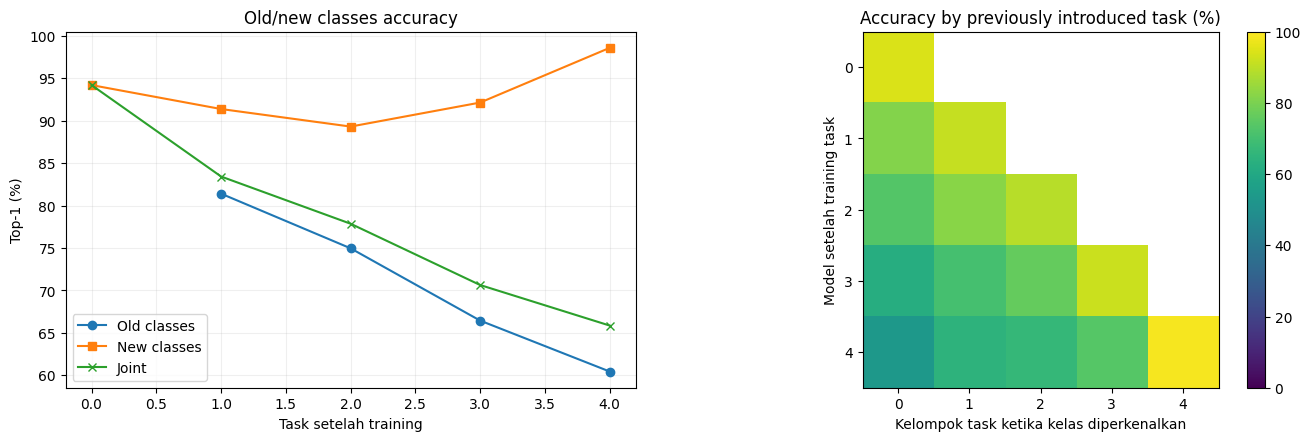

In [11]:
def task_group_diagnostics(row):
    run_dir = Path(row.run_dir)
    seen = list(row.seen_classes_curve)
    starts = [0] + seen[:-1]
    n_tasks, total_classes = len(seen), seen[-1]
    per_class = np.full((n_tasks, total_classes), np.nan)
    per_task = np.full((n_tasks, n_tasks), np.nan)
    grouped_rows = []
    for t in range(n_tasks):
        cm = np.load(run_dir / "confusion_matrices" / f"task_{t:02d}.npy", allow_pickle=False)
        diag, counts = np.diag(cm), cm.sum(axis=1)
        per_class[t, :seen[t]] = np.divide(diag, counts, out=np.zeros_like(diag, dtype=float), where=counts>0) * 100
        for j in range(t+1):
            start, end = starts[j], seen[j]
            per_task[t,j] = float(diag[start:end].sum() / counts[start:end].sum() * 100) if counts[start:end].sum() else np.nan
        old_end = starts[t]
        old = (float(diag[:old_end].sum() / counts[:old_end].sum() * 100)
               if old_end and counts[:old_end].sum() else np.nan)
        new = (float(diag[old_end:seen[t]].sum() / counts[old_end:seen[t]].sum() * 100)
               if counts[old_end:seen[t]].sum() else np.nan)
        grouped_rows.append({"task_id":t, "seen_classes":seen[t], "old_accuracy_pct":old,
                             "new_accuracy_pct":new, "joint_accuracy_pct":float(row.task_curve[t])})
    forgetting = np.nanmax(per_class, axis=0) - per_class[-1]
    fr_recomputed = float(np.nanmean(forgetting))
    bwt_recomputed = float(np.nanmean(per_task[-1,:-1] - np.diag(per_task)[:-1]))
    return pd.DataFrame(grouped_rows), per_task, per_class, forgetting, fr_recomputed, bwt_recomputed

if valid.empty:
    print("Belum ada hasil untuk diagnostik old/new.")
else:
    chosen = valid[(valid.dataset==SELECT_DATASET)&(valid.method==SELECT_METHOD)&
                   (valid.protocol==SELECT_PROTOCOL)&(valid.backbone==SELECT_BACKBONE)&
                   (valid.attention=="none")]
    if chosen.empty:
        chosen = valid[(valid.dataset==SELECT_DATASET)&(valid.method==SELECT_METHOD)&
                       (valid.protocol==SELECT_PROTOCOL)&(valid.backbone==SELECT_BACKBONE)]
    if chosen.empty:
        print("Konfigurasi diagnostik yang dipilih belum tersedia.")
    else:
        r = chosen.iloc[0]
        groups, task_matrix, class_matrix, class_forgetting, fr_calc, bwt_calc = task_group_diagnostics(r)
        display(Markdown(f"**{r.method.upper()} / {r.protocol} / {r.backbone.upper()} / {r.attention.upper()}**"))
        display(groups.round(2))
        print(f"FR stored: {r.fr}; computed from class histories: {fr_calc:.3f} (periksa skala/definisi bila berbeda)")
        print(f"BWT stored: {r.bwt}; computed from grouped task accuracies: {bwt_calc:.3f} (periksa skala/definisi bila berbeda)")
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), constrained_layout=True)
        axes[0].plot(groups.task_id, groups.old_accuracy_pct, marker='o', label='Old classes')
        axes[0].plot(groups.task_id, groups.new_accuracy_pct, marker='s', label='New classes')
        axes[0].plot(groups.task_id, groups.joint_accuracy_pct, marker='x', label='Joint')
        axes[0].set_xlabel('Task setelah training'); axes[0].set_ylabel('Top-1 (%)')
        axes[0].set_title('Old/new classes accuracy'); axes[0].legend(); axes[0].grid(alpha=.2)
        im=axes[1].imshow(task_matrix, vmin=0, vmax=100, cmap='viridis')
        axes[1].set_xlabel('Kelompok task ketika kelas diperkenalkan')
        axes[1].set_ylabel('Model setelah training task')
        axes[1].set_title('Accuracy by previously introduced task (%)')
        fig.colorbar(im, ax=axes[1]); plt.show()
        name=f"diagnostics_{r.method}_{r.protocol}_{r.backbone}_{r.attention}"
        groups.to_csv(OUTPUT_DIR/f"{name}_old_new.csv",index=False)
        pd.DataFrame(task_matrix).to_csv(OUTPUT_DIR/f"{name}_task_matrix.csv",index=False)


## 9. Confusion matrix akhir: baseline vs attention

Confusion matrix berasal dari prediksi canonical di **task terakhir**. Nilai heatmap ditampilkan **row-normalized (%)**, sehingga kelas AID yang jumlah citranya tidak seimbang tetap dapat dibandingkan secara adil dalam interpretasi *recall per class*. Detail kelas ditampilkan sebagai ID incremental `C00`, `C01`, dan seterusnya jika nama kelas asli tidak tersedia.

**Label kelas:** jangan mengasumsikan ID incremental sama dengan alphabetical original class ID. Jika sudah memiliki manifest `incremental_id → class_name` dari split seed 1993, isi `CLASS_LABELS` di bawah.

In [12]:
# Opsional: label yang BENAR berdasarkan mapping incremental class order yang dipakai.
# Contoh format: {"aid": {0: "nama_kelas_pertama", 1: "nama_kelas_kedua"}}
CLASS_LABELS = {}
COMPARE_ATTENTION = "procbam"  # eca | cbam | procbam


def fetch_cm(valid_runs, dataset, method, protocol, backbone, attention):
    required = {"dataset", "method", "protocol", "backbone", "attention", "run_dir"}
    if valid_runs is None or valid_runs.empty or not required.issubset(valid_runs.columns):
        return None, None
    subset = valid_runs[(valid_runs["dataset"] == dataset) & (valid_runs["method"] == method)
                        & (valid_runs["protocol"] == protocol) & (valid_runs["backbone"] == backbone)
                        & (valid_runs["attention"] == attention)]
    if len(subset) != 1:
        return None, None
    row = subset.iloc[0]
    cm_path = Path(row.run_dir) / "final_confusion_matrix.npy"
    if not cm_path.exists():
        return None, None
    cm = np.load(cm_path, allow_pickle=False)
    return row, cm


def normalize_rows(cm):
    cm = np.asarray(cm, dtype=float)
    return np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm), where=cm.sum(axis=1, keepdims=True)>0) * 100

row_none, cm_none = (None, None)
row_attn, cm_attn = (None, None)
if not valid.empty:
    row_none, cm_none = fetch_cm(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, "none")
    row_attn, cm_attn = fetch_cm(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, COMPARE_ATTENTION)

if cm_none is None or cm_attn is None:
    print("Baseline atau attention yang dipilih belum memiliki confusion matrix final valid.")

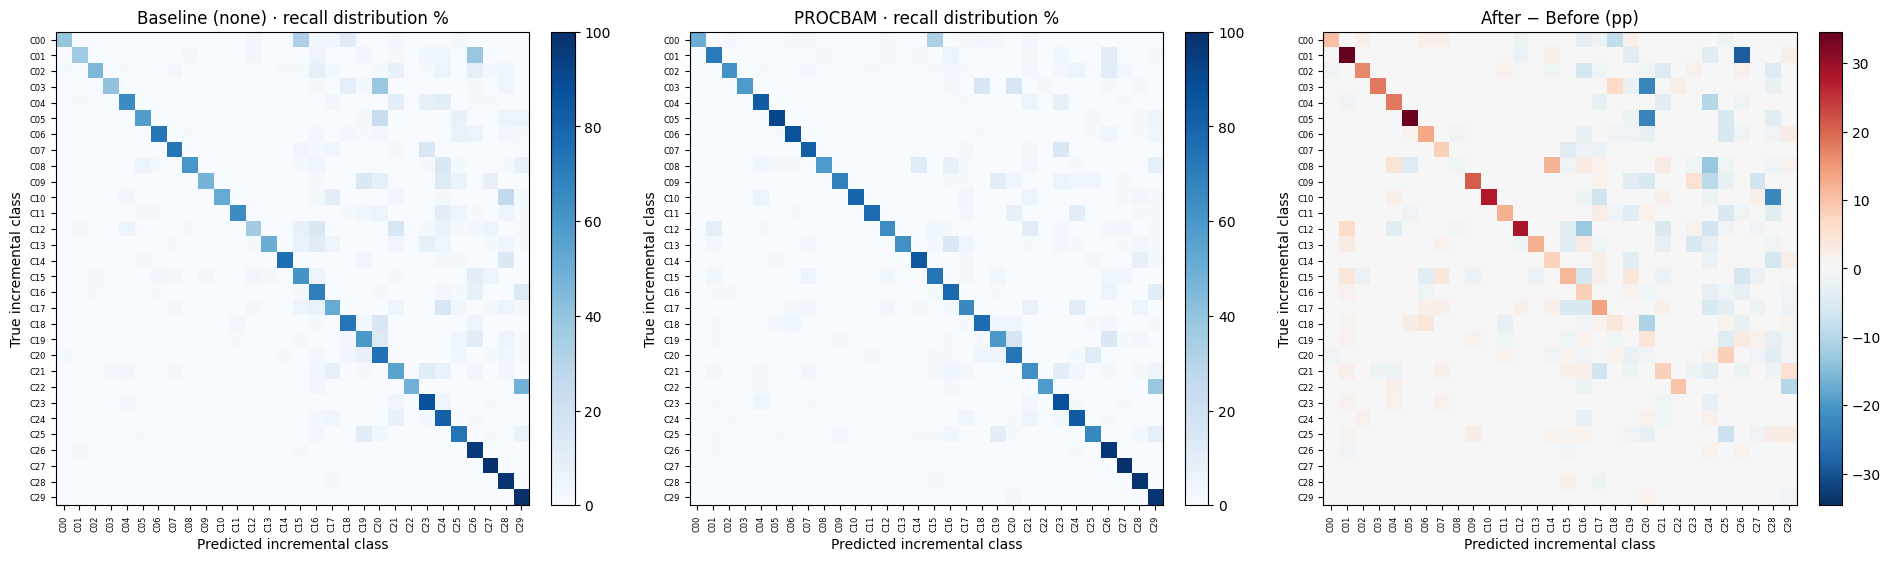

Top 10 perbaikan recall kelas:


,incremental_id,class_name,recall_none_pct,recall_attention_pct,delta_recall_pp
1,1,C01,36.54,71.15,34.62
5,5,C05,57.14,91.07,33.93
12,12,C12,35.90,64.10,28.21
10,10,C10,51.72,79.31,27.59
9,9,C09,47.37,68.42,21.05
4,4,C04,64.63,82.93,18.29
3,3,C03,40.91,59.09,18.18
2,2,C02,45.45,62.12,16.67
17,17,C17,51.72,65.52,13.79
6,6,C06,72.97,86.49,13.51


Top 10 penurunan recall kelas:


,incremental_id,class_name,recall_none_pct,recall_attention_pct,delta_recall_pp
25,25,C25,73.75,66.25,-7.50
29,29,C29,100.00,98.39,-1.61
8,8,C08,60.29,58.82,-1.47
20,20,C20,75.00,73.81,-1.19
19,19,C19,59.72,59.72,0.00
23,23,C23,87.14,87.14,0.00
27,27,C27,100.00,100.00,0.00
28,28,C28,98.33,98.33,0.00
26,26,C26,96.43,97.62,1.19
24,24,C24,81.43,82.86,1.43


Top 12 arah misclassification yang paling berkurang (perhatikan error baru yang bertambah):


,true_id,pred_id,true_class,pred_class,count_none,count_attn,decrease_in_errors,decrease_error_rate_pp
54,1,26,C01,C26,20,5,15,28.85
164,5,20,C05,C20,13,0,13,23.21
317,10,28,C10,C28,15,2,13,22.41
106,3,20,C03,C20,17,7,10,22.73
363,12,16,C12,C16,11,1,10,12.82
255,8,24,C08,C24,10,1,9,13.24
139,4,24,C04,C24,8,0,8,9.76
541,18,20,C18,C20,11,3,8,10.81
284,9,24,C09,C24,10,3,7,9.21
666,22,29,C22,C29,29,23,6,10.00


In [13]:
if cm_none is not None and cm_attn is not None:
    if cm_none.shape != cm_attn.shape or not np.array_equal(cm_none.sum(axis=1), cm_attn.sum(axis=1)):
        print("STOP: jumlah kelas atau true-label histogram berbeda; belum boleh membandingkan confusion matrix.")
    else:
        labels = [CLASS_LABELS.get(SELECT_DATASET, {}).get(i, f"C{i:02d}") for i in range(cm_none.shape[0])]
        before, after = normalize_rows(cm_none), normalize_rows(cm_attn)
        diff = after - before
        fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
        for ax, arr, title, cmap, scale in zip(
            axes, [before, after, diff],
            ["Baseline (none) · recall distribution %", f"{COMPARE_ATTENTION.upper()} · recall distribution %", "After − Before (pp)"],
            ["Blues", "Blues", "RdBu_r"],
            [(0, 100), (0, 100), (-max(1, np.abs(diff).max()), max(1, np.abs(diff).max()))]
        ):
            im = ax.imshow(arr, cmap=cmap, vmin=scale[0], vmax=scale[1], interpolation="nearest")
            ax.set_title(title)
            ax.set_xlabel("Predicted incremental class")
            ax.set_ylabel("True incremental class")
            if len(labels) <= 45:
                ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=6)
                ax.set_yticks(range(len(labels)), labels, fontsize=6)
            fig.colorbar(im, ax=ax, fraction=0.045, pad=0.04)
        if GENERATE_FIGURES:
            fig.savefig(OUTPUT_DIR / f"confusion_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.png", dpi=160)
        plt.show()

        # Recall per class / kelompok kelas yang paling meningkat atau menurun.
        delta_recall = np.diag(diff)
        class_table = pd.DataFrame({"incremental_id": range(len(labels)), "class_name": labels,
                                    "recall_none_pct": np.diag(before),
                                    "recall_attention_pct": np.diag(after),
                                    "delta_recall_pp": delta_recall})
        print("Top 10 perbaikan recall kelas:")
        display(class_table.nlargest(10, "delta_recall_pp").round(2))
        print("Top 10 penurunan recall kelas:")
        display(class_table.nsmallest(10, "delta_recall_pp").round(2))
        class_table.to_csv(OUTPUT_DIR / f"class_recall_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False)

        # High inter-class similarity: pasangan label keliru yang paling berkurang.
        pair_changes = []
        for i in range(cm_none.shape[0]):
            for j in range(cm_none.shape[1]):
                if i == j: continue
                pair_changes.append({"true_id": i, "pred_id": j, "true_class": labels[i],
                                    "pred_class": labels[j], "count_none": int(cm_none[i,j]),
                                    "count_attn": int(cm_attn[i,j]),
                                    "decrease_in_errors": int(cm_none[i,j] - cm_attn[i,j]),
                                    "decrease_error_rate_pp": float(before[i,j] - after[i,j])})
        changes_df = pd.DataFrame(pair_changes)
        print("Top 12 arah misclassification yang paling berkurang (perhatikan error baru yang bertambah):")
        display(changes_df.nlargest(12, "decrease_in_errors").round(2))
        changes_df.to_csv(OUTPUT_DIR / f"confusion_pair_changes_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False)

## 10. Ekspor tabel & ringkasan readiness

Notebook menyimpan laporan audit meskipun belum semua run lengkap. Hanya baris `eligible = True` digunakan dalam analisis. File CSV/JSON tetap dapat digunakan di Excel/Google Sheets atau untuk menulis Bab IV.

Catatan: **jangan gunakan grafik / ranking sementara untuk klaim akhir** sebelum pasangan baseline-vs-attention lengkap serta seluruh konflik diselesaikan. Pastikan klasifikasi hasil sesuai schema dan verifier `production_section.py` terkini.

In [14]:
def exportable(df):
    if df.empty: return df.copy()
    out = df.copy()
    for col in out.columns:
        if out[col].dtype == "object":
            out[col] = out[col].map(lambda v: json.dumps(v, ensure_ascii=False) if isinstance(v, (list, dict, tuple)) else v)
    return out

exports = {
    "run_audit.csv": runs,
    "valid_runs.csv": valid,
    "expected_coverage_aid.csv": coverage,
    "paired_attention_deltas.csv": paired,
    "rejected_unfair_pairs.csv": rejected_pairs,
    "attention_gain_summary.csv": gains,
}
for name, frame in exports.items():
    exportable(frame).to_csv(OUTPUT_DIR / name, index=False, encoding="utf-8-sig")

final_state = {
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "expected_aid_runs": int(len(coverage)),
    "valid_aid_runs": int(coverage["coverage"].str.startswith("ready").sum()),
    "run_candidates": int(len(runs)),
    "valid_in_scope": int(len(valid)),
    "paired_attention_comparisons": int(len(paired)),
    "rejected_unfair_pairs": int(len(rejected_pairs)),
    "duplicate_conflicts": int((runs["status"] == "duplicate_conflict").sum()) if not runs.empty else 0,
    "scope": DATASET_SCOPE,
    "single_training_seed": EXPECTED_SEED,
    "fwt": "not applicable under dynamic classifier protocol",
    "note": "Checkpoint inventory is source-only structural evidence, not proof of torch.load success.",
}
(OUTPUT_DIR / "analysis_status.json").write_text(json.dumps(final_state, indent=2), encoding="utf-8")
print(json.dumps(final_state, indent=2))
print("\nTabel dan gambar tersimpan di:", OUTPUT_DIR)

{
  "generated_at": "2026-11-12T00:07:14",
  "expected_aid_runs": 80,
  "valid_aid_runs": 80,
  "run_candidates": 80,
  "valid_in_scope": 80,
  "paired_attention_comparisons": 60,
  "rejected_unfair_pairs": 0,
  "duplicate_conflicts": 0,
  "scope": "aid",
  "single_training_seed": 1993,
  "fwt": "not applicable under dynamic classifier protocol",
  "note": "Checkpoint inventory is source-only structural evidence, not proof of torch.load success."
}

Tabel dan gambar tersimpan di: C:\Skripsi\Project\PyCIL\outputs\analysis


## 11. Kriteria siap untuk pembahasan Bab IV

1. **Coverage:** 80/80 AID run pada grid final jika semua lima metode dimasukkan. Jangan menyamakan target AID 80 run dengan proposal awal dua dataset (160 konfigurasi).
2. **Completeness:** masing-masing run mempunyai prediksi dan confusion matrix **setiap task**, `summary.json`, `continual_metrics.json`, config/provenance, serta checkpoint+method-state+manifest. Hasil `ready_snapshot` sebaiknya diverifikasi penuh di mesin sumber.
3. **Fairness:** keempat attention satu bundle memiliki metode, dataset, task order, seed, backbone, batch, dan hardware identik.
4. **Evaluasi utama:** nilai AIA dan LTA per run; ΔAIA/ΔLTA terhadap `none` pada paired bundle; Mean ΔAIA per metode/attention (laporkan `n_pairs`).
5. **Evaluasi tambahan:** Macro-F1, FR, BWT, kurva akurasi; analisis confusion pair pada kombinasi paling meningkat / paling menurun. FWT `not applicable` dan bukan nol.
6. **Interpretasi:** peningkatan paling besar secara deskriptif, **bukan signifikan secara statistik** ketika hanya seed 1993 yang digunakan.
7. **Dokumentasi:** simpan versi kode/commit, konfigurasi, sumber komputer, audit, hasil CSV dan gambar yang digunakan pada pembahasan.

*Notebook ini dibuat berdasarkan kontrak file runner/production section yang tersedia dalam konteks skripsi. Jika schema actual `config.json`, `continual_metrics.json`, atau `task_metrics.json` sudah berubah, tampilkan tabel audit untuk mengidentifikasi field yang harus disesuaikan sebelum melakukan analisis akhir.*

## 10B. Tabel utama Bab IV (AIA/LTA dan ΔAIA/ΔLTA)

Bagian ini menyiapkan **tabel yang siap dipakai untuk Bab IV** sesuai masukan terbaru:

- **Tabel 4.1–4.4**: AIA/LTA per protocol dalam bentuk tabel angka penuh.
- **Tabel 4.5–4.6**: ΔAIA/ΔLTA untuk **seluruh 60 pair** dibanding baseline `none`.

Seluruh tabel diekspor ke CSV dan, bila pustaka Excel tersedia, juga dikumpulkan ke workbook `bab4_main_tables.xlsx` agar mudah dicross-check.  

**Perbaikan v2.1:** konstruksi label baris mengonversi `Categorical` ke string sebelum penggabungan, kompatibel dengan pandas terbaru.


In [ ]:
def method_backbone_rows():
    return [f"{METHOD_LABELS[m]} / {b.upper()}" for m in METHODS for b in BACKBONES]


def build_main_metric_table(valid_runs: pd.DataFrame, protocol: str, metric_col: str, metric_label: str):
    cols = ["none", "eca", "cbam", "procbam"]
    if valid_runs.empty:
        return pd.DataFrame(columns=["method", "backbone"] + [ATTN_LABELS[c] for c in cols])
    sub = valid_runs[(valid_runs.dataset == DATASET_SCOPE) & (valid_runs.protocol == protocol)].copy()
    sub["method"] = pd.Categorical(sub["method"], METHODS, ordered=True)
    sub["backbone"] = pd.Categorical(sub["backbone"], BACKBONES, ordered=True)
    sub["row"] = sub["method"].astype(str).map(METHOD_LABELS).fillna(sub["method"].astype(str)) + " / " + sub["backbone"].astype(str).str.upper()
    piv = sub.pivot_table(index="row", columns="attention", values=metric_col, aggfunc="first")
    piv = piv.reindex(index=method_backbone_rows(), columns=cols)
    out = piv.rename(columns=ATTN_LABELS).reset_index().rename(columns={"row": "method_backbone"})
    out.insert(0, "protocol", protocol)
    out.insert(1, "metric", metric_label)
    return out


def build_pair_delta_table(pairs: pd.DataFrame, delta_col: str, sort_col: str):
    expected_cols = ["dataset", "method", "protocol", "backbone", "seed", "attention", "source_machine", "batch",
                     "baseline_run_id", "attention_run_id", sort_col, "baseline_aia_pct", "attention_aia_pct",
                     "baseline_lta_pct", "attention_lta_pct"]
    if pairs.empty:
        return pd.DataFrame(columns=expected_cols)
    out = pairs.copy()
    out["method"] = pd.Categorical(out["method"], METHODS, ordered=True)
    out["protocol"] = pd.Categorical(out["protocol"], PROTOCOLS, ordered=True)
    out["backbone"] = pd.Categorical(out["backbone"], BACKBONES, ordered=True)
    out["attention"] = pd.Categorical(out["attention"], PAIR_ATTENTIONS, ordered=True)
    out = out.sort_values(["protocol", "method", "backbone", "attention"]).reset_index(drop=True)
    return out


tbl_41 = build_main_metric_table(valid, "T5", "aia", "AIA")
tbl_42 = build_main_metric_table(valid, "T5", "lta", "LTA")
tbl_43 = build_main_metric_table(valid, "T10", "aia", "AIA")
tbl_44 = build_main_metric_table(valid, "T10", "lta", "LTA")
tbl_45 = build_pair_delta_table(paired, "delta_aia_pp", "delta_aia_pp")
tbl_46 = build_pair_delta_table(paired, "delta_lta_pp", "delta_lta_pp")

print("Tabel 4.1 — AIA T5")
display(tbl_41.round(2))
print("Tabel 4.2 — LTA T5")
display(tbl_42.round(2))
print("Tabel 4.3 — AIA T10")
display(tbl_43.round(2))
print("Tabel 4.4 — LTA T10")
display(tbl_44.round(2))
print("Tabel 4.5 — ΔAIA vs None (seluruh pair)")
display(tbl_45[["method","protocol","backbone","attention","delta_aia_pp","baseline_aia_pct","attention_aia_pct"]].round(2))
print("Tabel 4.6 — ΔLTA vs None (seluruh pair)")
display(tbl_46[["method","protocol","backbone","attention","delta_lta_pp","baseline_lta_pct","attention_lta_pct"]].round(2))

main_tables = {
    "table_4_1_aia_t5.csv": tbl_41,
    "table_4_2_lta_t5.csv": tbl_42,
    "table_4_3_aia_t10.csv": tbl_43,
    "table_4_4_lta_t10.csv": tbl_44,
    "table_4_5_delta_aia_pairs.csv": tbl_45,
    "table_4_6_delta_lta_pairs.csv": tbl_46,
}
for name, frame in main_tables.items():
    exportable(frame).to_csv(TABLE_DIR / name, index=False, encoding="utf-8-sig")

# Ringkas juga sebagai workbook Excel bila engine tersedia.
try:
    with pd.ExcelWriter(TABLE_DIR / "bab4_main_tables.xlsx") as xw:
        tbl_41.to_excel(xw, sheet_name="4.1_AIA_T5", index=False)
        tbl_42.to_excel(xw, sheet_name="4.2_LTA_T5", index=False)
        tbl_43.to_excel(xw, sheet_name="4.3_AIA_T10", index=False)
        tbl_44.to_excel(xw, sheet_name="4.4_LTA_T10", index=False)
        tbl_45.to_excel(xw, sheet_name="4.5_dAIA_pairs", index=False)
        tbl_46.to_excel(xw, sheet_name="4.6_dLTA_pairs", index=False)
    print("Workbook utama tersimpan:", TABLE_DIR / "bab4_main_tables.xlsx")
except Exception as exc:
    print("Workbook Excel tidak dibuat:", exc)


Tabel 4.1 — AIA T5


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T5,AIA,FeTrIL / R18,85.11,87.81,86.50,85.67
1,T5,AIA,FeTrIL / R34,84.41,86.13,87.63,85.88
2,T5,AIA,FeCAM / R18,87.66,86.94,88.37,88.32
3,T5,AIA,FeCAM / R34,83.01,84.97,84.95,84.15
4,T5,AIA,SSRE / R18,78.82,82.35,80.50,82.11
5,T5,AIA,SSRE / R34,77.68,80.83,79.65,80.28
6,T5,AIA,EFC / R18,76.88,78.36,81.45,82.39
7,T5,AIA,EFC / R34,76.01,77.38,79.71,80.08
8,T5,AIA,PASS / R18,78.39,84.33,80.85,83.70
9,T5,AIA,PASS / R34,81.24,82.33,80.93,82.87


Tabel 4.2 — LTA T5


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T5,LTA,FeTrIL / R18,77.80,81.45,78.75,77.50
1,T5,LTA,FeTrIL / R34,76.05,78.30,80.70,78.50
2,T5,LTA,FeCAM / R18,81.45,80.80,83.10,82.45
3,T5,LTA,FeCAM / R34,75.45,78.40,77.90,77.20
4,T5,LTA,SSRE / R18,69.85,74.20,71.65,73.25
5,T5,LTA,SSRE / R34,69.15,73.80,70.55,72.20
6,T5,LTA,EFC / R18,71.35,73.75,76.90,78.50
7,T5,LTA,EFC / R34,70.90,72.90,75.00,75.45
8,T5,LTA,PASS / R18,65.85,76.75,69.65,75.60
9,T5,LTA,PASS / R34,74.90,76.25,74.00,76.55


Tabel 4.3 — AIA T10


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T10,AIA,FeTrIL / R18,78.26,82.61,81.32,81.49
1,T10,AIA,FeTrIL / R34,78.80,84.10,80.16,80.80
2,T10,AIA,FeCAM / R18,83.16,83.41,85.39,85.83
3,T10,AIA,FeCAM / R34,77.59,79.34,78.95,78.48
4,T10,AIA,SSRE / R18,71.79,77.60,74.43,76.00
5,T10,AIA,SSRE / R34,69.87,75.27,74.90,75.76
6,T10,AIA,EFC / R18,69.86,70.64,76.62,76.04
7,T10,AIA,EFC / R34,69.58,70.21,74.00,75.52
8,T10,AIA,PASS / R18,67.16,74.60,64.44,68.92
9,T10,AIA,PASS / R34,70.38,73.66,70.60,72.51


Tabel 4.4 — LTA T10


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T10,LTA,FeTrIL / R18,67.25,74.40,72.70,71.85
1,T10,LTA,FeTrIL / R34,69.40,77.00,70.85,71.75
2,T10,LTA,FeCAM / R18,76.20,76.10,79.25,79.90
3,T10,LTA,FeCAM / R34,68.20,70.80,70.40,70.95
4,T10,LTA,SSRE / R18,61.70,70.35,66.15,67.75
5,T10,LTA,SSRE / R34,60.95,68.30,64.75,65.65
6,T10,LTA,EFC / R18,64.40,65.90,71.50,72.65
7,T10,LTA,EFC / R34,64.75,65.95,69.70,70.85
8,T10,LTA,PASS / R18,49.55,58.85,39.35,45.85
9,T10,LTA,PASS / R34,61.10,64.00,56.45,60.35


Tabel 4.5 — ΔAIA vs None (seluruh pair)


KeyError: "['delta_aia_pp', 'baseline_aia_pct', 'attention_aia_pct'] not in index"

: 

## 10C. Heatmap ΔAIA, ΔLTA, ΔFR, dan ΔBWT

Sesuai arahan Bab IV, efek attention divisualisasikan dengan heatmap agar pola peningkatan/penurunan cepat terlihat:

- **ΔAIA** dan **ΔLTA**: nilai positif = lebih baik dari baseline.
- **ΔFR**: nilai **negatif** = forgetting berkurang (lebih baik).
- **ΔBWT**: nilai lebih tinggi biasanya lebih baik / lebih tidak negatif.

Baris merepresentasikan **metode × backbone × protocol**, kolom merepresentasikan **ECA / CBAM / ProCBAM**.  

In [ ]:
def build_delta_heatmap_matrix(pairs: pd.DataFrame, value_col: str):
    if pairs.empty:
        return pd.DataFrame()
    sub = pairs.copy()
    sub["method"] = pd.Categorical(sub["method"], METHODS, ordered=True)
    sub["backbone"] = pd.Categorical(sub["backbone"], BACKBONES, ordered=True)
    sub["protocol"] = pd.Categorical(sub["protocol"], PROTOCOLS, ordered=True)
    sub["row"] = sub["method"].astype(str).map(METHOD_LABELS).fillna(sub["method"].astype(str)) + " / " + sub["backbone"].astype(str).str.upper() + " / " + sub["protocol"].astype(str)
    mat = sub.pivot_table(index="row", columns="attention", values=value_col, aggfunc="first")
    desired_rows = [f"{METHOD_LABELS[m]} / {b.upper()} / {p}" for m in METHODS for b in BACKBONES for p in PROTOCOLS]
    mat = mat.reindex(index=desired_rows, columns=list(PAIR_ATTENTIONS))
    return mat.rename(columns=ATTN_LABELS)


def plot_heatmap(df: pd.DataFrame, title: str, save_name: str, center: float = 0.0, note: str | None = None, smaller_is_better: bool = False):
    if df.empty:
        print(f"Heatmap '{title}' belum dapat dibuat karena data kosong.")
        return
    arr = df.to_numpy(dtype=float)
    finite = np.isfinite(arr)
    vmax = np.nanmax(np.abs(arr[finite])) if finite.any() else 1.0
    vmax = max(1.0, float(vmax))
    fig_h = max(6, 0.42 * len(df))
    fig, ax = plt.subplots(figsize=(8.8, fig_h), constrained_layout=True)
    im = ax.imshow(arr, cmap="RdYlGn_r" if smaller_is_better else "RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_title(title)
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=0)
    ax.set_yticks(range(df.shape[0]), df.index, fontsize=8)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            val = df.iat[i, j]
            text = "" if pd.isna(val) else f"{val:.2f}"
            ax.text(j, i, text, ha="center", va="center", fontsize=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.030, pad=0.02)
    cbar.set_label("percentage points (pp)")
    if note:
        ax.set_xlabel(note)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / save_name, dpi=180, bbox_inches="tight")
    plt.show()

heat_delta_aia = build_delta_heatmap_matrix(paired, "delta_aia_pp")
heat_delta_lta = build_delta_heatmap_matrix(paired, "delta_lta_pp")
heat_delta_fr = build_delta_heatmap_matrix(paired, "delta_fr_pp")
heat_delta_bwt = build_delta_heatmap_matrix(paired, "delta_bwt_pp")

# Simpan data sumber heatmap untuk keperluan cek manual.
exportable(heat_delta_aia.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_aia_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_lta.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_lta_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_fr.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_fr_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_bwt.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_bwt_source.csv", index=False, encoding="utf-8-sig")

plot_heatmap(heat_delta_aia, "Heatmap ΔAIA vs None", "heatmap_delta_aia.png")
plot_heatmap(heat_delta_lta, "Heatmap ΔLTA vs None", "heatmap_delta_lta.png")
plot_heatmap(heat_delta_fr, "Heatmap ΔFR vs None (negatif = forgetting turun / lebih baik)", "heatmap_delta_fr.png", smaller_is_better=True)
plot_heatmap(heat_delta_bwt, "Heatmap ΔBWT vs None", "heatmap_delta_bwt.png")


## 10D. Grouped bar chart untuk *old* vs *new* accuracy

Visual ini membantu menjelaskan **stability vs plasticity**. Secara default, notebook membuat dua level analisis:

1. **Ringkasan bundle**: rata-rata `old-class accuracy` dan `new-class accuracy` pada seluruh task untuk `None`, `ECA`, `CBAM`, dan `ProCBAM` pada satu bundle terpilih.
2. **Tabel detail task-wise**: per task, `None` vs attention tertentu dapat dicross-check bila diperlukan.

Gunakan selector di bawah untuk memilih bundle yang ingin dimasukkan ke naskah.  

In [ ]:
OLDNEW_DATASET = SELECT_DATASET
OLDNEW_METHOD = SELECT_METHOD
OLDNEW_PROTOCOL = SELECT_PROTOCOL
OLDNEW_BACKBONE = SELECT_BACKBONE


def get_run(valid_runs, dataset, method, protocol, backbone, attention):
    required = {"dataset", "method", "protocol", "backbone", "attention"}
    if valid_runs is None or valid_runs.empty or not required.issubset(valid_runs.columns):
        return None
    subset = valid_runs[(valid_runs["dataset"] == dataset) & (valid_runs["method"] == method) &
                        (valid_runs["protocol"] == protocol) & (valid_runs["backbone"] == backbone) &
                        (valid_runs["attention"] == attention)]
    return None if subset.empty else subset.iloc[0]


def summarize_bundle_old_new(valid_runs, dataset, method, protocol, backbone):
    rows = []
    taskwise_rows = []
    for attn in ATTENTIONS:
        run = get_run(valid_runs, dataset, method, protocol, backbone, attn)
        if run is None:
            continue
        groups, task_matrix, class_matrix, class_forgetting, fr_calc, bwt_calc = task_group_diagnostics(run)
        avg_old = groups["old_accuracy_pct"].dropna().mean() if "old_accuracy_pct" in groups else np.nan
        avg_new = groups["new_accuracy_pct"].dropna().mean() if "new_accuracy_pct" in groups else np.nan
        avg_joint = groups["joint_accuracy_pct"].dropna().mean() if "joint_accuracy_pct" in groups else np.nan
        rows.append({
            "dataset": dataset, "method": method, "protocol": protocol, "backbone": backbone,
            "attention": attn, "avg_old_accuracy_pct": avg_old, "avg_new_accuracy_pct": avg_new,
            "avg_joint_accuracy_pct": avg_joint, "run_id": run.run_id,
        })
        tmp = groups.copy()
        tmp.insert(0, "dataset", dataset)
        tmp.insert(1, "method", method)
        tmp.insert(2, "protocol", protocol)
        tmp.insert(3, "backbone", backbone)
        tmp.insert(4, "attention", attn)
        tmp.insert(5, "run_id", run.run_id)
        taskwise_rows.append(tmp)
    return pd.DataFrame(rows), (pd.concat(taskwise_rows, ignore_index=True) if taskwise_rows else pd.DataFrame())

bundle_oldnew, taskwise_oldnew = summarize_bundle_old_new(valid, OLDNEW_DATASET, OLDNEW_METHOD, OLDNEW_PROTOCOL, OLDNEW_BACKBONE)
if bundle_oldnew.empty:
    print("Belum ada data old/new accuracy untuk bundle yang dipilih.")
else:
    order = [a for a in ATTENTIONS if a in bundle_oldnew["attention"].tolist()]
    plot_df = bundle_oldnew.set_index("attention").reindex(order).reset_index()
    x = np.arange(len(plot_df))
    w = 0.36
    fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
    ax.bar(x - w/2, plot_df["avg_old_accuracy_pct"], width=w, label="Old classes")
    ax.bar(x + w/2, plot_df["avg_new_accuracy_pct"], width=w, label="New classes")
    ax.set_xticks(x, [ATTN_LABELS[a] for a in plot_df["attention"]])
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"Old vs New Accuracy — {METHOD_LABELS.get(OLDNEW_METHOD, OLDNEW_METHOD)} / {OLDNEW_BACKBONE.upper()} / {OLDNEW_PROTOCOL}")
    ax.legend()
    ax.grid(axis="y", alpha=.25)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / f"old_new_grouped_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.png", dpi=180, bbox_inches="tight")
    plt.show()
    display(bundle_oldnew.round(2))
    exportable(bundle_oldnew).to_csv(TABLE_DIR / f"old_new_summary_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.csv", index=False, encoding="utf-8-sig")
    exportable(taskwise_oldnew).to_csv(TABLE_DIR / f"old_new_taskwise_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.csv", index=False, encoding="utf-8-sig")


## 10E. *Class accuracy* — diverging horizontal bar chart

Untuk pembahasan **performa antar kelas**, grafik yang paling komunikatif adalah **diverging horizontal bar chart**. 

Secara default grafik dibuat untuk pasangan yang sedang dipilih pada Section 9 (`SELECT_METHOD`, `SELECT_PROTOCOL`, `SELECT_BACKBONE`, `COMPARE_ATTENTION`). Grafik menampilkan kelas dengan kenaikan terbesar dan penurunan terbesar pada **task final**.  

In [ ]:
TOP_N_CLASS_DELTA = 8


def class_delta_from_confusion(valid_runs, dataset, method, protocol, backbone, attention, class_labels=None):
    row_none, cm_none = fetch_cm(valid_runs, dataset, method, protocol, backbone, "none")
    row_attn, cm_attn = fetch_cm(valid_runs, dataset, method, protocol, backbone, attention)
    if cm_none is None or cm_attn is None:
        return pd.DataFrame()
    if cm_none.shape != cm_attn.shape:
        return pd.DataFrame()
    labels = [CLASS_LABELS.get(dataset, {}).get(i, f"C{i:02d}") for i in range(cm_none.shape[0])]
    norm_none, norm_attn = normalize_rows(cm_none), normalize_rows(cm_attn)
    tbl = pd.DataFrame({
        "class_id": range(cm_none.shape[0]),
        "class_name": labels,
        "recall_none_pct": np.diag(norm_none),
        "recall_attention_pct": np.diag(norm_attn),
        "delta_recall_pp": np.diag(norm_attn - norm_none),
        "support": cm_none.sum(axis=1).astype(int),
    })
    return tbl

class_delta_tbl = class_delta_from_confusion(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, COMPARE_ATTENTION)
if class_delta_tbl.empty:
    print("Class accuracy delta belum dapat dibuat untuk pasangan yang dipilih.")
else:
    pos = class_delta_tbl.nlargest(TOP_N_CLASS_DELTA, "delta_recall_pp")
    neg = class_delta_tbl.nsmallest(TOP_N_CLASS_DELTA, "delta_recall_pp")
    plot_tbl = pd.concat([neg, pos], ignore_index=True)
    plot_tbl = plot_tbl.sort_values("delta_recall_pp")
    y = np.arange(len(plot_tbl))
    colors = ["tab:red" if v < 0 else "tab:green" for v in plot_tbl["delta_recall_pp"]]
    fig, ax = plt.subplots(figsize=(9.5, max(5, 0.42*len(plot_tbl))), constrained_layout=True)
    ax.barh(y, plot_tbl["delta_recall_pp"], color=colors)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y, [f"{r.class_name} (n={int(r.support)})" for _, r in plot_tbl.iterrows()])
    ax.set_xlabel("Δ class accuracy / recall (pp)")
    ax.set_title(f"Perubahan Class Accuracy — {METHOD_LABELS.get(SELECT_METHOD, SELECT_METHOD)} / {SELECT_BACKBONE.upper()} / {SELECT_PROTOCOL} / {ATTN_LABELS.get(COMPARE_ATTENTION, COMPARE_ATTENTION)}")
    ax.grid(axis="x", alpha=.25)
    for yi, v in enumerate(plot_tbl["delta_recall_pp"]):
        ax.text(v + (0.4 if v >= 0 else -0.4), yi, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / f"class_delta_diverging_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.png", dpi=180, bbox_inches="tight")
    plt.show()
    display(plot_tbl.round(2))
    exportable(class_delta_tbl).to_csv(TABLE_DIR / f"class_accuracy_delta_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False, encoding="utf-8-sig")


## 10F. *Confusion matrix* representatif

Sesuai arahan, confusion matrix **tidak** ditampilkan untuk semua model. Notebook ini otomatis memilih **2 kasus peningkatan paling besar** dan **1 kasus penurunan paling jelas** berdasarkan `ΔAIA`, lalu membuat heatmap:

- baseline `None`
- attention terpilih
- selisih `(attention − baseline)`

Anda tetap dapat mengganti daftar representatif secara manual bila ingin memilih kasus tertentu seperti **PASS + CBAM**.  

In [ ]:
def representative_pairs_from_paired(pairs: pd.DataFrame, top_pos: int = 2, top_neg: int = 1):
    if pairs.empty:
        return pd.DataFrame()
    pos = pairs.nlargest(top_pos, "delta_aia_pp")
    neg = pairs.nsmallest(top_neg, "delta_aia_pp")
    out = pd.concat([pos, neg], ignore_index=True).drop_duplicates(subset=["method","protocol","backbone","attention"])
    return out

rep_pairs = representative_pairs_from_paired(paired, top_pos=2, top_neg=1)
if rep_pairs.empty:
    print("Belum ada pasangan representatif yang bisa diplot.")
else:
    display(rep_pairs[["method","protocol","backbone","attention","delta_aia_pp","delta_lta_pp"]].round(2))
    rep_rows = []
    for r in rep_pairs.itertuples(index=False):
        rn, cmn = fetch_cm(valid, r.dataset, r.method, r.protocol, r.backbone, "none")
        ra, cma = fetch_cm(valid, r.dataset, r.method, r.protocol, r.backbone, r.attention)
        if cmn is None or cma is None or cmn.shape != cma.shape:
            continue
        labels = [CLASS_LABELS.get(r.dataset, {}).get(i, f"C{i:02d}") for i in range(cmn.shape[0])]
        before, after = normalize_rows(cmn), normalize_rows(cma)
        diff = after - before
        vmax = max(1.0, float(np.abs(diff).max()))
        fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), constrained_layout=True)
        specs = [
            (before, "Blues", 0, 100, "Baseline (None)"),
            (after, "Blues", 0, 100, ATTN_LABELS.get(r.attention, r.attention)),
            (diff, "RdBu_r", -vmax, vmax, "Attention − None (pp)"),
        ]
        for ax, (arr, cmap, vmin, vmax0, title) in zip(axes, specs):
            im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax0, interpolation="nearest")
            ax.set_title(title)
            ax.set_xlabel("Predicted class")
            ax.set_ylabel("True class")
            if len(labels) <= 30:
                ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=6)
                ax.set_yticks(range(len(labels)), labels, fontsize=6)
            fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
        suptitle = f"Confusion Matrix — {METHOD_LABELS.get(r.method, r.method)} / {r.backbone.upper()} / {r.protocol} / {ATTN_LABELS.get(r.attention, r.attention)}"
        fig.suptitle(suptitle, fontsize=12)
        if GENERATE_FIGURES:
            fig.savefig(FIG_DIR / f"representative_confusion_{r.method}_{r.protocol}_{r.backbone}_{r.attention}.png", dpi=180, bbox_inches="tight")
        plt.show()
        rep_rows.append({
            "method": r.method, "protocol": r.protocol, "backbone": r.backbone, "attention": r.attention,
            "delta_aia_pp": r.delta_aia_pp, "delta_lta_pp": r.delta_lta_pp,
            "figure_file": f"representative_confusion_{r.method}_{r.protocol}_{r.backbone}_{r.attention}.png",
        })
    rep_df = pd.DataFrame(rep_rows)
    if not rep_df.empty:
        exportable(rep_df).to_csv(TABLE_DIR / "representative_confusion_cases.csv", index=False, encoding="utf-8-sig")


## 10G. Cross-check dengan seluruh tabel AI analysis

Bagian ini memuat **semua tabel hasil AI-ready analysis** agar dapat dibandingkan langsung dengan tabel utama Bab IV. Notebook mencoba membaca sumber data dari salah satu lokasi berikut:

1. folder `outputs/analysis_ai_ready/`
2. file ZIP `outputs/analysis_ai_ready/ai_ready_evaluation_bundle.zip`
3. file ZIP di lokasi yang Anda tentukan manual.

Jika tersedia, seluruh CSV akan disalin ke `outputs/analysis/ai_crosscheck/` dan juga dirangkum ke workbook Excel.  

In [ ]:
AI_BUNDLE_OVERRIDE = None  # isi Path(...) bila zip berada di lokasi lain
AI_EXPECTED_FILES = [
    "valid_runs.csv", "paired_attention_effects.csv", "method_attention_gain.csv",
    "task_attention_delta.csv", "class_attention_delta.csv", "misclassification_delta.csv",
    "model_insights_all.csv", "bundle_insights_all.csv", "attention_insights_all.csv",
    "class_insights_final_all.csv", "AI_EVIDENCE_REPORT.md",
]


def load_ai_ready_tables(ai_dir: Path, ai_zip_override=None):
    loaded = {}
    missing = []
    source = None
    if ai_dir.is_dir() and any((ai_dir / name).exists() for name in AI_EXPECTED_FILES):
        source = "directory"
        for name in AI_EXPECTED_FILES:
            path = ai_dir / name
            if path.exists():
                if path.suffix.lower() == ".csv":
                    loaded[name] = pd.read_csv(path)
                else:
                    loaded[name] = path.read_text(encoding="utf-8")
            else:
                missing.append(name)
        return source, loaded, missing

    zip_path = None
    if ai_zip_override is not None:
        zip_path = Path(ai_zip_override)
    elif (ai_dir / "ai_ready_evaluation_bundle.zip").exists():
        zip_path = ai_dir / "ai_ready_evaluation_bundle.zip"
    if zip_path and zip_path.exists():
        source = f"zip:{zip_path}"
        with zipfile.ZipFile(zip_path) as zf:
            names = set(zf.namelist())
            for name in AI_EXPECTED_FILES:
                if name in names:
                    if name.endswith(".csv"):
                        with zf.open(name) as fh:
                            loaded[name] = pd.read_csv(fh)
                    else:
                        loaded[name] = zf.read(name).decode("utf-8")
                else:
                    missing.append(name)
        return source, loaded, missing

    return None, loaded, AI_EXPECTED_FILES.copy()

source, ai_loaded, ai_missing = load_ai_ready_tables(AI_READY_DIR, AI_BUNDLE_OVERRIDE)
if source is None:
    print("AI-ready outputs belum ditemukan. Bagian cross-check dilewati.")
else:
    print("Sumber AI-ready:", source)
    print("File ditemukan:", sorted(ai_loaded.keys()))
    if ai_missing:
        print("File belum tersedia:", ai_missing)
    manifest_rows = []
    for name, obj in ai_loaded.items():
        if isinstance(obj, pd.DataFrame):
            exportable(obj).to_csv(AI_CROSSCHECK_DIR / name, index=False, encoding="utf-8-sig")
            manifest_rows.append({"file": name, "rows": len(obj), "cols": len(obj.columns), "type": "csv"})
        else:
            (AI_CROSSCHECK_DIR / name).write_text(obj, encoding="utf-8")
            manifest_rows.append({"file": name, "rows": np.nan, "cols": np.nan, "type": "text"})
    manifest_df = pd.DataFrame(manifest_rows)
    display(manifest_df)
    exportable(manifest_df).to_csv(AI_CROSSCHECK_DIR / "ai_crosscheck_manifest.csv", index=False, encoding="utf-8-sig")

    # Workbook untuk cross-check seluruh tabel AI.
    try:
        with pd.ExcelWriter(AI_CROSSCHECK_DIR / "ai_crosscheck_tables.xlsx") as xw:
            for name, obj in ai_loaded.items():
                if isinstance(obj, pd.DataFrame):
                    sheet = name.replace(".csv", "")[:31]
                    obj.to_excel(xw, sheet_name=sheet, index=False)
        print("Workbook AI cross-check tersimpan:", AI_CROSSCHECK_DIR / "ai_crosscheck_tables.xlsx")
    except Exception as exc:
        print("Workbook AI cross-check tidak dibuat:", exc)

    # Tampilkan beberapa tabel kunci agar bisa langsung dicross-check di notebook.
    for key in ["model_insights_all.csv", "bundle_insights_all.csv", "attention_insights_all.csv", "class_insights_final_all.csv"]:
        if key in ai_loaded and isinstance(ai_loaded[key], pd.DataFrame):
            print(f"Preview: {key}")
            display(ai_loaded[key].head(10))


## 10H. Ringkasan file output untuk Bab IV

Setelah seluruh sel di atas dijalankan, file penting untuk penulisan Bab IV akan berada di dua folder berikut:

- `outputs/analysis/tables_bab4/`
- `outputs/analysis/figures/`

Sedangkan seluruh tabel hasil AI untuk keperluan *cross-check* akan berada di:

- `outputs/analysis/ai_crosscheck/`

Dengan struktur ini, Anda dapat memisahkan **tabel/grafik yang masuk naskah** dari **tabel audit/internal** yang hanya dipakai untuk verifikasi.  

In [ ]:
summary_rows = []
for folder in [TABLE_DIR, FIG_DIR, AI_CROSSCHECK_DIR]:
    if folder.exists():
        for p in sorted(folder.iterdir()):
            if p.is_file():
                summary_rows.append({
                    "folder": str(folder.relative_to(PROJECT_ROOT)),
                    "file": p.name,
                    "size_kb": round(p.stat().st_size / 1024, 2),
                })
summary_df = pd.DataFrame(summary_rows)
if summary_df.empty:
    print("Belum ada file output tambahan yang dibuat.")
else:
    display(summary_df)
    exportable(summary_df).to_csv(OUTPUT_DIR / "bab4_output_inventory.csv", index=False, encoding="utf-8-sig")
